# This is a _Regression Model_ of Houston's 2024 Housing Costs from Zillow.

This is an analysis of the City of Houston's housing 2024 prices - with 25,000+ listings scrapped off of Zillow.


These are the libraries I used for the analysis of Zillow's housing analysis. SQLite was my database of choice, due to the relatively compact amounts of data provided.

In [32]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt

In [33]:
table_name = "properties"
db_path = "houston_housing.db"
conn = sqlite3.connect(db_path)
cursor = conn.cursor()


cursor.execute(f"PRAGMA table_info({table_name});")
schema_info = cursor.fetchall()

int_column = [col[1] for col in schema_info if "INT" in col[2].upper()]

if int_column:
    print(f"The following columns are available: {int_column}")


The following columns are available: ['zpid', 'isListingClaimedByCurrentSignedInUser', 'isCurrentSignedInAgentResponsible', 'bedrooms', 'bathrooms', 'price', 'yearBuilt', 'isCurrentSignedInUserVerifiedOwner', 'isRentalListingOffMarket', 'cityId', 'isUndisclosedAddress', 'isShowcaseListing', 'isPremierBuilder', 'monthlyHoaFee', 'livingArea', 'livingAreaValue', 'zestimate', 'rentZestimate', 'pageViewCount', 'favoriteCount', 'daysOnZillow', 'ssid', 'isZillowOwned', 'hasApprovedThirdPartyVirtualTourUrl', 'photoCount', 'lotSize', 'stateId', 'hasBadGeocode', 'hasPublicVideo', 'tourViewCount', 'hideZestimate', 'isPreforeclosureAuction', 'isHousingConnector', 'isRecentStatusChange', 'isNonOwnerOccupied', 'isFeatured', 'isRentalsLeadCapMet', 'isPaidMultiFamilyBrokerId', 'countyId', 'isValid']


In [34]:
df = pd.read_sql(df_sql1, conn)

df = df.apply(pd.to_numeric, errors="coerce")

cols_keep_name = ["yearBuilt", "zestimate", "rentZestimate"]
cols_fill = df.columns.difference(cols_keep_name)
df[cols_fill] = df[cols_fill].fillna(0)

print(df.isna().sum())

df = df.dropna().reset_index(drop=True)

X_train = df.drop(columns=["price"]).to_numpy()
y_train = df["price"].to_numpy()

print(f"X shape: {X_train.shape}, X Type: {type(X_train)}")
print(f"y shape: {y_train.shape}, y Type: {type(y_train)}")

conn.close()

bedrooms           0
bathrooms          0
yearBuilt          1
monthlyHoaFee      0
livingArea         0
livingAreaValue    0
zestimate          9
rentZestimate      6
daysOnZillow       0
price              0
dtype: int64
X shape: (76, 9), X Type: <class 'numpy.ndarray'>
y shape: (76,), y Type: <class 'numpy.ndarray'>


Text(0, 0.5, 'Price')

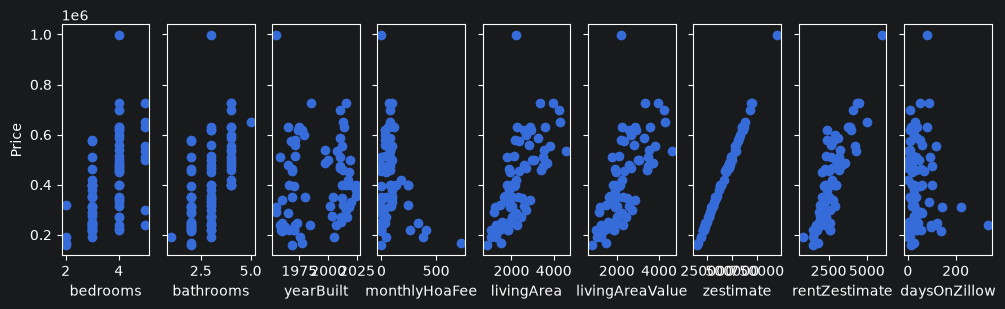

In [74]:
X_features = ["bedrooms", "bathrooms", "yearBuilt", "monthlyHoaFee", "livingArea", "livingAreaValue", "zestimate", "rentZestimate", "daysOnZillow"]

fig,ax=plt.subplots(1, 9, figsize=(12,3), sharey=True)

for i in range(len(ax)):
    ax[i].scatter(X_train[:,i],y_train)
    ax[i].set_xlabel(X_features[i])
ax[0].set_ylabel("Price")

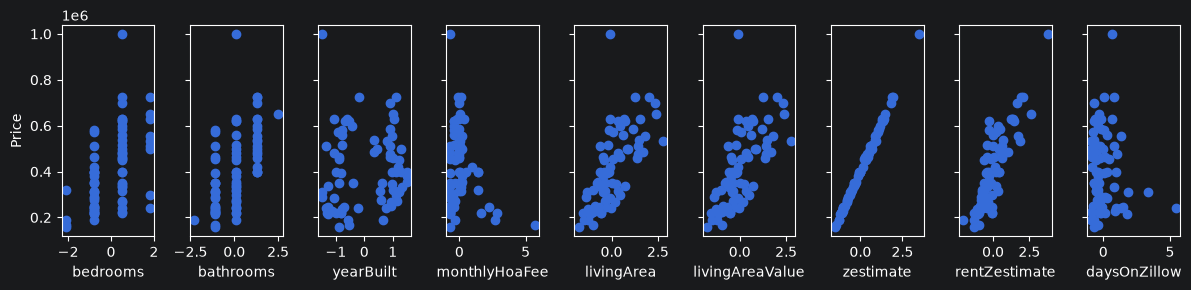

In [67]:
def zscaled_features():
    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1

    x_features_scaled = (X_train - mu) / sigma
    return x_features_scaled

x_scaled = zscaled_features()
fig, ax = plt.subplots(1, 9, figsize=(12, 3), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(x_scaled[:, i], y_train)
    ax[i].set_xlabel(X_features[i])
ax[0].set_ylabel("Price")
plt.tight_layout()
plt.show()

In [77]:
def compute_cost(X, y, w, b):
    m = len(y)
    err = X @ w + b - y
    return (err @ err) / (2 * m)

cost = compute_cost(x_scaled, y_train, w_init, b_init)
print(cost)

95473697961.2171


In [49]:
def compute_gradient(X, y, w, b):

    dj_dw = np.zeros_like(w, dtype=float)
    dj_db = 0.0
    m = X.shape[0]

    for i in range(m):
        f_wb = np.dot(x_scaled[i], w) + b
        err = f_wb - y[i]
        dj_dw += err * X[i]
        dj_db += err

    dj_dw = (dj_dw / m)
    dj_db = (dj_db / m)
    return dj_dw, dj_db

In [50]:
tmp_dj_dw, tmp_dj_db = compute_gradient(x_scaled, y_train, w_init, b_init)
print("Gradient at initial w, b (zeros):")
print("dj_dw:", tmp_dj_dw)
print("dj_db:", tmp_dj_db)

Gradient at initial w, b (zeros):
dj_dw: [ -86662.16462144  -92785.4149992   -18937.76449195   27580.39658872
 -114478.18667664 -114478.18667664 -164681.51230057 -141623.88907905
   15739.20618794]
dj_db: -404703.7763157895


In [51]:
def gradient_descent(X, y, w, b, alpha, num_iters):
    w = np.array(w, dtype=float)
    b = float(b)
    cost_history = []

    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        cost_history.append(compute_cost(X, y, w, b))

        if i % max(1, num_iters // 10) == 0:
            print(f"Iteration {i:4d}: cost {cost_history[-1]:.2f}")

    return w, b, cost_history

Iteration    0: cost 72867040393.06
Iteration  100: cost 75376439.06
Iteration  200: cost 18104768.14
Iteration  300: cost 11331925.46
Iteration  400: cost 10510159.17
Iteration  500: cost 10410216.96
Iteration  600: cost 10398058.81
Iteration  700: cost 10396579.71
Iteration  800: cost 10396399.76
Iteration  900: cost 10396377.87
Gradient Descent found by:
w: [  -421.11112207   -211.84889922  -2020.13515638    316.86180877
  -1115.54922388  -1115.54922388 165766.69859809   1766.57833515
   3107.71462931]
b: 404703.77631578926


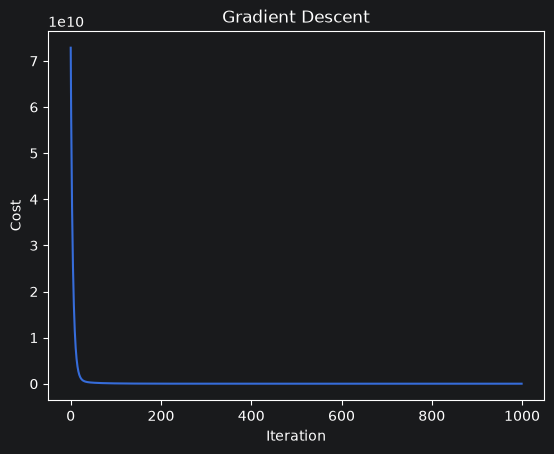

In [86]:
alpha = 0.1
iterations = 1000

final_w, final_b, cost_history = gradient_descent(
    x_scaled, y_train, w_init, b_init, alpha, iterations)

print("Gradient Descent found by:")
print("w:", final_w)
print("b:", final_b)

plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Gradient Descent")
plt.show()

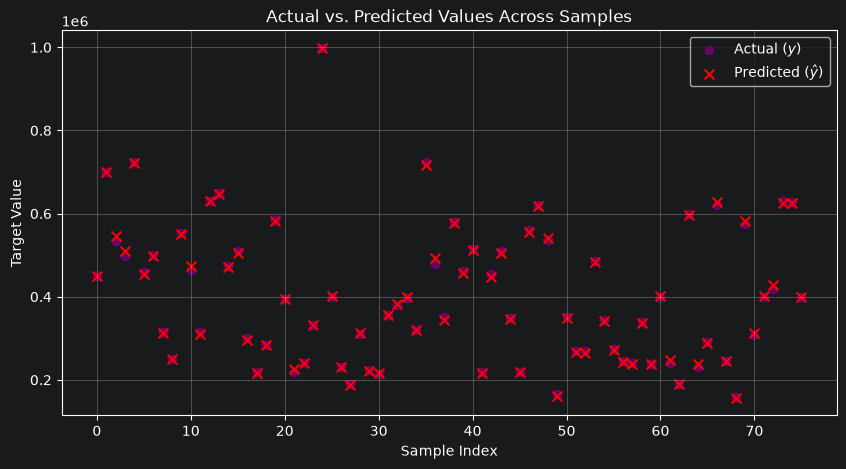

In [96]:
predicted = x_scaled @ w_final + b_final

# Create a sample index for the x-axis
sample_indices = np.arange(len(y_train))

plt.figure(figsize=(10, 5))
plt.scatter(sample_indices, y_train, color='purple', label='Actual ($y$)', alpha=0.7)
plt.scatter(sample_indices, predicted, color='red', marker='x', label=r'Predicted ($\hat{y}$)', s=50)

plt.title("Actual vs. Predicted Values Across Samples")
plt.xlabel("Sample Index")
plt.ylabel("Target Value")
plt.legend()
plt.grid(True)
plt.show()